# Fisher forecasts with FIONA

This notebook walks through the Fisher-forecast part of the paper. It reproduces the LISA and LIGO forecasts for a cored isothermal sphere (CIS) lens.

1. Compute the lensing amplification factor $F(w, y)$ with FIONA.
2. See which part of $F$ each detector's sources probe.
3. Turn the Fisher covariances into marginalized uncertainties and confidence ellipses.

The covariances behind the paper's figures ship in `data/fisher_covariances.npz`, so the notebook runs in seconds. To recompute them, run `python scripts/1_fisher/fisher_forecasts.py compute`.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='Wswiglal')   # silence a LALSuite notice in Jupyter

import finufft  # must be imported before FIONA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths, quadrature, table
from infer_with_fiona.fiona.axisym import FresnelNUFHTLensBatched
from infer_with_fiona.fisher import f_isco, f_1month
from infer_with_fiona.fisher.utils import G_over_c3_Msun

## 1. The amplification factor

A lens of redshifted mass $M_{Lz}$ multiplies the gravitational waveform by $F(w, y, x_c)$. Here
$$w = 8\pi \frac{G M_{Lz}}{c^3} f$$
is the dimensionless frequency, $y$ is the source position and $x_c$ is the CIS core radius, both in units of the Einstein radius.

FIONA evaluates $F$ for a whole set of source positions in one call. We use the converged Gauss-Legendre schedule (`cis`) and the paper's fiducial lens, $x_c = 0.01$.

In [2]:
quadrature.get_schedule('cis').apply()

XC = 0.01
w = np.logspace(-2, 2, 400)
y_values = np.array([0.3, 1.0, 3.0])

solver = FresnelNUFHTLensBatched([table.make_lens('CIS', XC)], gl_dir=str(paths.GL_RULES_DIR),
                                 n_workers=8, print_timing=False)
F = solver(w, y_values)[:, 0, :]          # shape (n_w, n_y): one call for all source positions
F.shape

(400, 3)

At low $w$ the wavelength is much larger than the lens, the wave diffracts around it, and $F \to 1$. At high $w$, $F$ approaches the geometric-optics sum over images, $F_{\rm GO} = \sum_j \sqrt{|\mu_j|}\, e^{i w T_j - i\pi n_j}$, whose interference produces the oscillations.

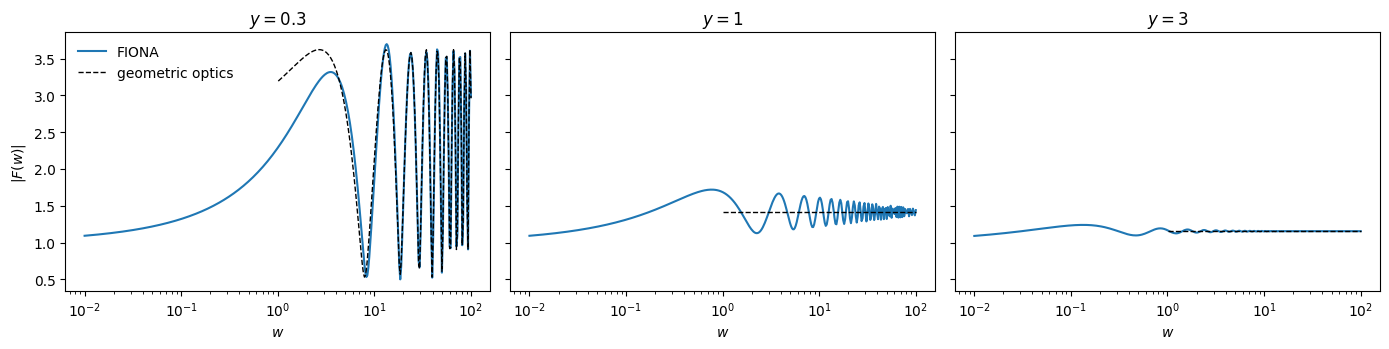

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, y, Fy in zip(axes, y_values, F.T):
    ax.semilogx(w, np.abs(Fy), color='tab:blue', lw=1.5, label='FIONA')
    w_go = w[w > 1]
    ax.semilogx(w_go, np.abs(table.F_go(w_go, *table.cis_image_set(XC, y))), 'k--', lw=1, label='geometric optics')
    ax.set(title=rf'$y = {y:g}$', xlabel='$w$')
axes[0].set_ylabel(r'$|F(w)|$')
axes[0].legend(frameon=False)
plt.tight_layout()

## 2. Which part of $F$ each detector sees

The forecasts put the lens at $M_{Lz} = 10^5\,M_\odot$, $y = 0.3$ and $x_c = 0.01$. A source contributes signal from the lowest frequency in band up to its innermost stable circular orbit, $f_{\rm ISCO}$. For LISA we keep the last month before merger, as in Tambalo et al. (2023).

Converting that frequency range to $w$ shows where each source sits relative to the wave-optics regime, $w \sim 1$.

In [4]:
M_LZ, Y_FID = 1e5, 0.3
w_of = lambda f: 8 * np.pi * G_over_c3_Msun * M_LZ * f

SOURCES = {  # detector: [(name, m1, m2)], source redshift, band [Hz]
    'LISA': ([('SMBHB 1e4+1e4', 1e4, 1e4), ('SMBHB 1e5+1e5', 1e5, 1e5), ('SMBHB 1e6+1e6', 1e6, 1e6)], 3.0, (1e-4, 1.0)),
    'LIGO': ([('BNS 1.4+1.4', 1.4, 1.4), ('NSBH 10+1.4', 10, 1.4), ('BBH 10+10', 10, 10),
              ('BBH 30+30', 30, 30), ('BBH 60+60', 60, 60)], 0.1, (10.0, 1000.0)),
}
rows = []
for det, (srcs, z_s, (f_min, f_max)) in SOURCES.items():
    for name, m1, m2 in srcs:
        M, eta = m1 + m2, m1 * m2 / (m1 + m2) ** 2
        f_lo, f_hi = max(f_1month(M, eta, z_s), f_min), min(f_isco(M, z_s), f_max)
        rows.append(dict(detector=det, source=name, w_min=w_of(f_lo), w_max=w_of(f_hi)))
bands = pd.DataFrame(rows)
bands.style.format({'w_min': '{:.2g}', 'w_max': '{:.2g}'}).hide(axis='index')

detector,source,w_min,w_max
LISA,SMBHB 1e4+1e4,0.011,0.68
LISA,SMBHB 1e5+1e5,0.0025,0.068
LISA,SMBHB 1e6+1e6,0.0012,0.0068
LIGO,BNS 1.4+1.4,1.2e+02,1.2e+04
LIGO,NSBH 10+1.4,1.2e+02,4.3e+03
LIGO,BBH 10+10,1.2e+02,2.5e+03
LIGO,BBH 30+30,1.2e+02,8.2e+02
LIGO,BBH 60+60,1.2e+02,4.1e+02


Only the lightest LISA binary approaches $w \sim 1$, where $F$ departs from unity and depends on the core. The heavier LISA binaries stay at $w \ll 1$. Every LIGO source sits deep in the geometric-optics regime, $w \gtrsim 10^2$, where the signal is set mainly by the image time delay and magnification ratio.

## 3. From Fisher matrix to constraints

For a signal $\tilde h_L(f; \boldsymbol\theta) = F(w, y, x_c)\,\tilde h_0(f)\,e^{i\varphi_0}$ in Gaussian noise with power spectral density $S_n(f)$, the Fisher matrix is
$$F_{ij} = 4\,\mathrm{Re}\int \frac{df}{S_n(f)}\,\frac{\partial \tilde h_L^*}{\partial\theta_i}\frac{\partial \tilde h_L}{\partial\theta_j},
\qquad \boldsymbol\theta = (\ln M_{Lz},\, y,\, x_c,\, \ln D_L,\, \varphi_0).$$
FIONA provides the derivatives of $F$ by central finite differences, batching $y \pm \varepsilon$ and $x_c \pm \varepsilon$ into the same call. The distance and phase are marginalized over, which leaves a $3\times3$ covariance for $(\ln M_{Lz}, y, x_c)$.

The Fisher matrix scales as $\varrho^2$, the squared signal-to-noise ratio. So we quote every source at a common SNR, $\varrho_{\rm fid} = 10^3$ for LISA and $10^2$ for LIGO, by rescaling the covariance by $(\varrho/\varrho_{\rm fid})^2$.

In [5]:
data = np.load(paths.FISHER_COVARIANCES)
SNR_FID = {'LISA': 1e3, 'LIGO': 1e2}
KEYS = {'SMBHB 1e4+1e4': 'SMBHB_1e4', 'SMBHB 1e5+1e5': 'SMBHB_1e5', 'SMBHB 1e6+1e6': 'SMBHB_1e6',
        'BNS 1.4+1.4': 'BNS', 'NSBH 10+1.4': 'NSBH', 'BBH 10+10': 'BBH_10', 'BBH 30+30': 'BBH_30', 'BBH 60+60': 'BBH_60'}


def covariance(det, name):
    """Covariance of (ln M_Lz, y, x_c) rescaled to the fiducial SNR of the detector."""
    k = f'{det}_{KEYS[name]}'
    return data[f'{k}_cov'] * (float(data[f'{k}_snr']) / SNR_FID[det]) ** 2


rows = []
for det, (srcs, _, _) in SOURCES.items():
    for name, *_ in srcs:
        sigma = np.sqrt(np.diag(covariance(det, name)))
        rows.append({'detector': det, 'source': name, 'SNR_fid': SNR_FID[det],
                     'σ(ln M_Lz)': sigma[0], 'σ(y)': sigma[1], 'σ(x_c)': sigma[2]})
pd.DataFrame(rows).style.format({'SNR_fid': '{:.0f}', 'σ(ln M_Lz)': '{:.2g}', 'σ(y)': '{:.2g}', 'σ(x_c)': '{:.2g}'}).hide(axis='index')

detector,source,SNR_fid,σ(ln M_Lz),σ(y),σ(x_c)
LISA,SMBHB 1e4+1e4,1000,0.02,0.022,0.029
LISA,SMBHB 1e5+1e5,1000,0.02,0.069,0.097
LISA,SMBHB 1e6+1e6,1000,0.019,0.086,0.61
LIGO,BNS 1.4+1.4,100,0.0019,0.00046,0.0003
LIGO,NSBH 10+1.4,100,0.0029,0.00073,0.00047
LIGO,BBH 10+10,100,0.0036,0.00089,0.00058
LIGO,BBH 30+30,100,0.0071,0.0018,0.0011
LIGO,BBH 60+60,100,0.012,0.003,0.0019


### Confidence ellipses

A Gaussian with covariance $C$ has its 68% and 95% contours at $\Delta\chi^2 = 2.30$ and $5.99$ in two dimensions. The function below draws them for every parameter pair, with the 1D marginals on the diagonal.

In [6]:
from matplotlib.patches import Ellipse

LABELS = [r'$\Delta \ln M_{Lz}$', r'$y$', r'$x_c$']
CENTER = np.array([0.0, Y_FID, XC])
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']


def fisher_corner(covs, names, title):
    fig, axes = plt.subplots(3, 3, figsize=(7, 7))
    span = 3.5 * np.max([np.sqrt(np.diag(c)) for c in covs], axis=0)
    for c, name, col in zip(covs, names, COLORS):
        for i in range(3):
            x = np.linspace(-span[i], span[i], 300)
            sd = np.sqrt(c[i, i])
            axes[i, i].plot(CENTER[i] + x, np.exp(-0.5 * (x / sd) ** 2), color=col, label=name)
            for j in range(i):
                sub = c[np.ix_([j, i], [j, i])]
                vals, vecs = np.linalg.eigh(sub)
                angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
                for chi2, alpha in ((2.30, 0.4), (5.99, 0.15)):
                    width, height = 2 * np.sqrt(chi2 * np.maximum(vals[::-1], 0))
                    axes[i, j].add_patch(Ellipse((CENTER[j], CENTER[i]), width, height, angle=angle,
                                                 facecolor=col, alpha=alpha, lw=0))
                    axes[i, j].add_patch(Ellipse((CENTER[j], CENTER[i]), width, height, angle=angle,
                                                 fill=False, edgecolor=col, lw=1.0))   # outline: some ellipses are very thin
    for i in range(3):
        for j in range(3):
            ax = axes[i, j]
            if j > i:
                ax.axis('off')
                continue
            ax.set_xlim(CENTER[j] - span[j], CENTER[j] + span[j])
            if j < i:
                ax.set_ylim(CENTER[i] - span[i], CENTER[i] + span[i])
            else:
                ax.set_yticks([])
            if i == 2:
                ax.set_xlabel(LABELS[j])
            else:
                ax.set_xticklabels([])
            if j == 0 and i > 0:
                ax.set_ylabel(LABELS[i])
            elif j > 0:
                ax.set_yticklabels([])
    axes[0, 0].legend(loc='upper left', bbox_to_anchor=(1.3, 1.0), frameon=False)
    fig.suptitle(title)
    return fig

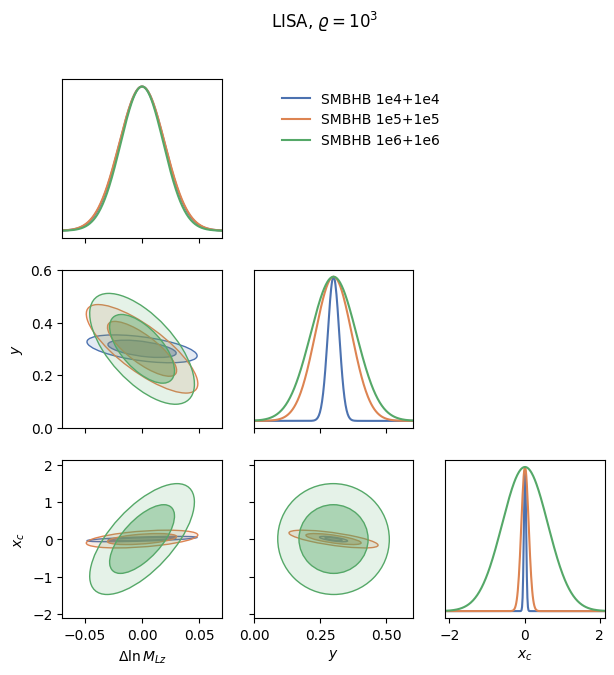

In [7]:
names = [s[0] for s in SOURCES['LISA'][0]]
fisher_corner([covariance('LISA', n) for n in names], names, r'LISA, $\varrho = 10^3$');

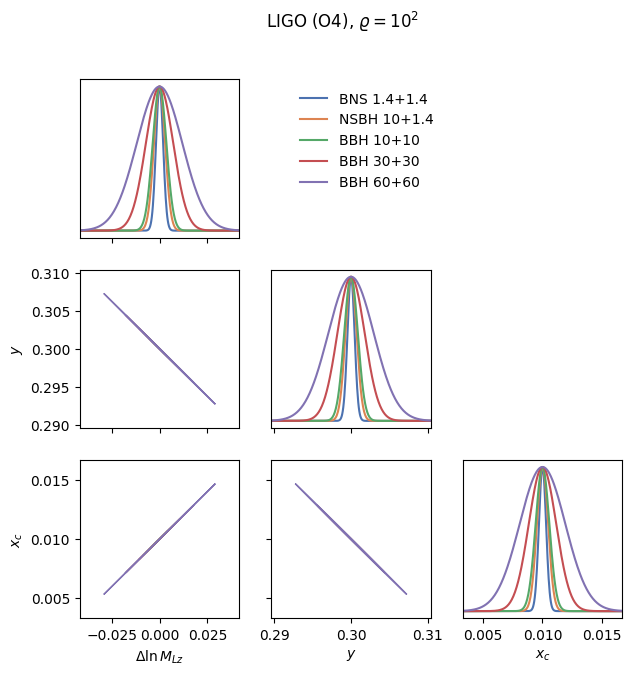

In [8]:
names = [s[0] for s in SOURCES['LIGO'][0]]
fisher_corner([covariance('LIGO', n) for n in names], names, r'LIGO (O4), $\varrho = 10^2$');

## Summary

- **LISA.** At equal SNR, all three binaries measure $\ln M_{Lz}$ about equally well. The lightest binary gives much tighter constraints on $y$ and $x_c$, because it is the only one whose signal approaches $w \sim 1$, where $F$ depends on the core. The heavier binaries accumulate their signal at $w \ll 1$, where $F \approx 1$.
- **LIGO.** At this lens mass every LIGO source is in the geometric-optics regime. Two observables, the image time delay and the magnification ratio, constrain only two combinations of the three lens parameters, so the ellipses are nearly one-dimensional along a degeneracy set by the lens. The source only sets how far along it the constraint extends.